# 04 — Sales & Inventory Analysis

**Input:** validated data from `data/cleaned/`
**Purpose:** answer the core business questions about sales performance and inventory.

## Questions

1. **Revenue & Profit** — What are the headline numbers?
2. **Products** — Which products and categories drive revenue?
3. **Stores** — Which stores, cities, and locations perform best?
4. **Time** — How has revenue trended over time?
5. **Inventory** — How much capital is tied up in stock? Where is it concentrated?
6. **Opportunities** — What actions do these patterns suggest?

Every section ends with **written findings**, not just a chart.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Better-looking defaults
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Paths
base = Path("C:/Users/selin/anaconda_projects/data science/Retail-Sales-Inventory-Project/data/cleaned")

# Load cleaned tables — re-parse dates since CSV flattens them
sales     = pd.read_csv(base / "sales_clean.csv",     parse_dates=["Date"])
products  = pd.read_csv(base / "products_clean.csv")
stores    = pd.read_csv(base / "stores_clean.csv",    parse_dates=["Store_Open_Date"])
inventory = pd.read_csv(base / "inventory_clean.csv")

# ---------------------------------------------------------------
# Build the analysis dataframe: sales enriched with product + store + stock
# Left joins so every sale is preserved even if a dimension is missing.
# ---------------------------------------------------------------
data = (
    sales
    .merge(products,  on="Product_ID", how="left")
    .merge(stores,    on="Store_ID",   how="left")
    .merge(inventory, on=["Store_ID", "Product_ID"], how="left")
)

# Derived business metrics
data["Revenue"]         = data["Units"] * data["Product_Price"]
data["Cost"]            = data["Units"] * data["Product_Cost"]
data["Profit"]          = data["Revenue"] - data["Cost"]
data["Profit_Margin"]   = data["Profit"] / data["Revenue"]
data["Inventory_Value"] = data["Stock_On_Hand"] * data["Product_Cost"]

# Time helpers
data["Year"]    = data["Date"].dt.year
data["Month"]   = data["Date"].dt.to_period("M").astype(str)
data["Quarter"] = data["Date"].dt.to_period("Q").astype(str)

print(f"Analysis dataframe: {data.shape[0]:,} rows × {data.shape[1]} columns")
print(f"Date range: {data['Date'].min().date()} → {data['Date'].max().date()}")
data.head()

Analysis dataframe: 829,262 rows × 22 columns
Date range: 2022-01-01 → 2023-09-30


,Sale_ID,Date,Store_ID,Product_ID,Units,Product_Name,Product_Category,Product_Cost,Product_Price,Store_Name,...,Store_Open_Date,Stock_On_Hand,Revenue,Cost,Profit,Profit_Margin,Inventory_Value,Year,Month,Quarter
0,1,2022-01-01,24,4,1,Chutes & Ladders,Games,9.99,12.99,Maven Toys Aguascalientes 1,...,2010-07-31,1.0,12.99,9.99,3.0,0.230947,9.99,2022,2022-01,2022Q1
1,2,2022-01-01,28,1,1,Action Figure,Toys,9.99,15.99,Maven Toys Puebla 2,...,2011-04-01,6.0,15.99,9.99,6.0,0.375235,59.94,2022,2022-01,2022Q1
2,3,2022-01-01,6,8,1,Deck Of Cards,Games,3.99,6.99,Maven Toys Mexicali 1,...,2003-12-13,50.0,6.99,3.99,3.0,0.429185,199.50,2022,2022-01,2022Q1
3,4,2022-01-01,48,7,1,Dart Gun,Sports & Outdoors,11.99,15.99,Maven Toys Saltillo 2,...,2016-03-23,28.0,15.99,11.99,4.0,0.250156,335.72,2022,2022-01,2022Q1
4,5,2022-01-01,44,18,1,Lego Bricks,Toys,34.99,39.99,Maven Toys Puebla 3,...,2014-12-27,117.0,39.99,34.99,5.0,0.125031,4093.83,2022,2022-01,2022Q1


### Findings

- **Revenue:** $X across the period
- **Profit margin:** X% overall
- **Units sold:** X
- **Inventory value:** $X

The headline margin tells us whether pricing is healthy at an aggregate
level. We'll break it down by product and store next to see if any
segments drag it down.

## 2. Products — What Drives Revenue?

Two views:

1. **By product** — top revenue earners, margin leaders, and loss-makers
2. **By category** — where does the business focus its revenue?

We care about both **revenue** (scale) and **margin** (profitability).
A high-revenue, low-margin product may be less valuable than a
lower-revenue, high-margin one.

In [3]:
# ---------------------------------------------------------------
# 2.1 By product
# ---------------------------------------------------------------
product_perf = (
    data.groupby(["Product_ID", "Product_Name", "Product_Category"], as_index=False)
        .agg(Revenue=("Revenue", "sum"),
             Profit=("Profit", "sum"),
             Units=("Units", "sum"))
)
product_perf["Margin"] = product_perf["Profit"] / product_perf["Revenue"]

# Top 10 by revenue
top_by_revenue = product_perf.sort_values("Revenue", ascending=False).head(10)

# Top 10 by margin (min revenue filter so tiny sellers don't dominate)
top_by_margin = (
    product_perf[product_perf["Revenue"] > product_perf["Revenue"].quantile(0.5)]
    .sort_values("Margin", ascending=False)
    .head(10)
)

# Loss-makers (margin < 0)
loss_makers = product_perf[product_perf["Margin"] < 0].sort_values("Margin")

print("Top 10 products by revenue:")
display(top_by_revenue.round(2))

print("\nTop 10 products by margin (above median revenue):")
display(top_by_margin.round(2))

print("\nLoss-making products:", len(loss_makers))
display(loss_makers.round(2))

Top 10 products by revenue:


,Product_ID,Product_Name,Product_Category,Revenue,Profit,Units,Margin
17,18,Lego Bricks,Toys,2388882.63,298685.0,59737,0.13
5,6,Colorbuds,Electronics,1564476.32,834944.0,104368,0.53
18,19,Magic Sand,Art & Crafts,968962.02,121196.0,60598,0.13
0,1,Action Figure,Toys,926748.42,347748.0,57958,0.38
29,30,Rubik's Cube,Games,912983.28,91344.0,45672,0.10
7,8,Deck Of Cards,Games,587397.66,252102.0,84034,0.43
30,31,Splash Balls,Sports & Outdoors,541629.52,60248.0,60248,0.11
23,24,Nerf Gun,Sports & Outdoors,530594.57,132715.0,26543,0.25
1,2,Animal Figures,Toys,507766.11,117267.0,39089,0.23
6,7,Dart Gun,Sports & Outdoors,505092.12,126352.0,31588,0.25



Top 10 products by margin (above median revenue):


,Product_ID,Product_Name,Product_Category,Revenue,Profit,Units,Margin
5,6,Colorbuds,Electronics,1564476.32,834944.0,104368,0.53
2,3,Barrel O' Slime,Art & Crafts,365735.37,183326.0,91663,0.50
13,14,Glass Marbles,Games,412322.82,187590.0,37518,0.45
7,8,Deck Of Cards,Games,587397.66,252102.0,84034,0.43
0,1,Action Figure,Toys,926748.42,347748.0,57958,0.38
20,21,Mini Ping Pong Set,Sports & Outdoors,335703.96,100812.0,33604,0.30
16,17,Kids Makeup Kit,Art & Crafts,488415.67,146598.0,24433,0.30
12,13,Gamer Headphones,Electronics,376938.42,107748.0,17958,0.29
9,10,Dinosaur Figures,Toys,434889.88,116048.0,29012,0.27
6,7,Dart Gun,Sports & Outdoors,505092.12,126352.0,31588,0.25



Loss-making products: 0


,Product_ID,Product_Name,Product_Category,Revenue,Profit,Units,Margin


C:\Users\selin\AppData\Local\Temp\ipykernel_14716\2655162579.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_by_revenue, y="Product_Name", x="Revenue", ax=ax, palette="viridis")


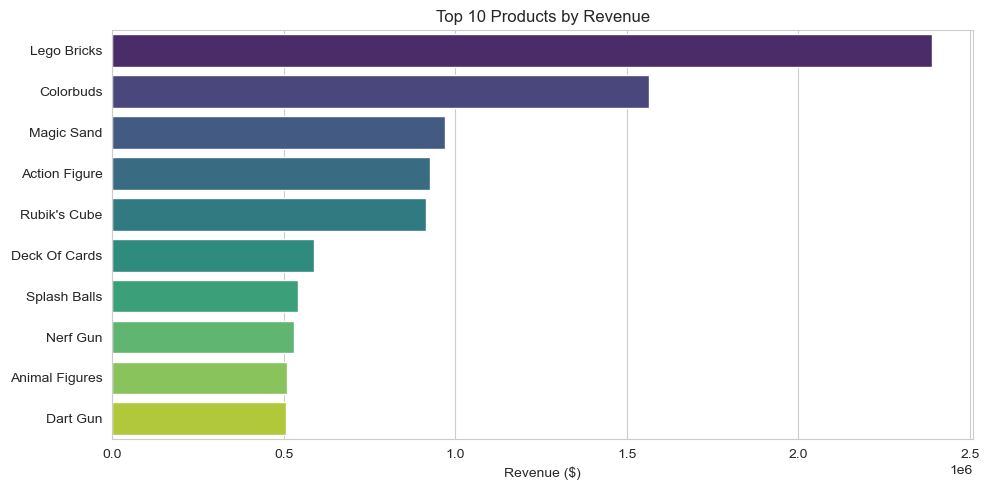

In [5]:
# ---------------------------------------------------------------
# 2.2 Chart: top 10 by revenue
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top_by_revenue, y="Product_Name", x="Revenue", ax=ax, palette="viridis")
ax.set_title("Top 10 Products by Revenue")
ax.set_xlabel("Revenue ($)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Findings

- **Top category by revenue:** ___ (X% of total revenue)
- **Most profitable category:** ___ (X% margin)
- **Loss-makers:** ___ products with negative margin

**Action:** Focus marketing and stock on high-revenue, high-margin
products. Investigate any loss-makers — are they mispriced, or are
costs higher than expected?

## 3. Stores — Where Does Revenue Come From?

Three levels of granularity:

1. **By store** — top performers, bottom performers
2. **By city** — geographic concentration
3. **By location type** — Downtown vs Mall vs Airport etc.

We'll also check whether newer stores perform differently from
older ones (using `Store_Open_Date`).

In [7]:
# ---------------------------------------------------------------
# 3.1 By store
# ---------------------------------------------------------------
store_perf = (
    data.groupby(["Store_ID", "Store_Name", "Store_City", "Store_Location"], as_index=False)
        .agg(Revenue=("Revenue", "sum"),
             Profit=("Profit", "sum"),
             Units=("Units", "sum"),
             Transactions=("Sale_ID", "count"))
)
store_perf["Margin"] = store_perf["Profit"] / store_perf["Revenue"]
store_perf["Avg_Transaction"] = store_perf["Revenue"] / store_perf["Transactions"]

top_stores    = store_perf.sort_values("Revenue", ascending=False).head(10)
bottom_stores = store_perf.sort_values("Revenue", ascending=True).head(10)

print("Top 10 stores by revenue:")
display(top_stores.round(2))

print("\nBottom 10 stores by revenue:")
display(bottom_stores.round(2))

Top 10 stores by revenue:


,Store_ID,Store_Name,Store_City,Store_Location,Revenue,Profit,Units,Transactions,Margin,Avg_Transaction
30,31,Maven Toys Ciudad de Mexico 2,Cuidad de Mexico,Airport,554553.43,169856.0,42757,29024,0.31,19.11
29,30,Maven Toys Guadalajara 3,Guadalajara,Airport,449354.91,121571.0,31609,23384,0.27,19.22
8,9,Maven Toys Ciudad de Mexico 1,Cuidad de Mexico,Downtown,433556.21,111296.0,33479,24482,0.26,17.71
16,17,Maven Toys Toluca 1,Toluca,Downtown,411157.32,104612.0,32668,23533,0.25,17.47
6,7,Maven Toys Monterrey 2,Monterrey,Downtown,372998.82,106783.0,28318,21300,0.29,17.51
45,46,Maven Toys Guadalajara 4,Guadalajara,Downtown,348466.64,102178.0,24136,18739,0.29,18.60
41,42,Maven Toys Hermosillo 3,Hermosillo,Commercial,344846.64,98825.0,23236,16553,0.29,20.83
38,39,Maven Toys Xalapa 2,Xalapa,Downtown,344307.04,88637.0,25296,18809,0.26,18.31
36,37,Maven Toys Ciudad de Mexico 3,Cuidad de Mexico,Residential,337424.66,94021.0,26634,19551,0.28,17.26
3,4,Maven Toys Saltillo 1,Saltillo,Downtown,330408.90,94252.0,24010,18924,0.29,17.46



Bottom 10 stores by revenue:


,Store_ID,Store_Name,Store_City,Store_Location,Revenue,Profit,Units,Transactions,Margin,Avg_Transaction
25,26,Maven Toys Campeche 2,Campeche,Commercial,206055.23,58091.0,16277,12805,0.28,16.09
4,5,Maven Toys La Paz 1,La Paz,Downtown,210897.83,57407.0,16217,13217,0.27,15.96
10,11,Maven Toys Cuernavaca 1,Cuernavaca,Downtown,221587.26,56811.0,17074,13643,0.26,16.24
42,43,Maven Toys Durango 1,Durango,Downtown,222318.78,62673.0,17422,14110,0.28,15.76
39,40,Maven Toys Toluca 2,Toluca,Commercial,222364.36,58090.0,15964,12776,0.26,17.40
14,15,Maven Toys Tuxtla Gutierrez 1,Tuxtla Gutierrez,Downtown,229698.27,65787.0,19773,14618,0.29,15.71
19,20,Maven Toys Zacatecas 1,Zacatecas,Downtown,229983.04,59160.0,17196,13501,0.26,17.03
17,18,Maven Toys Merida 1,Merida,Downtown,232097.72,64399.0,18328,14875,0.28,15.60
31,32,Maven Toys Hermosillo 1,Hermosillo,Residential,235115.18,76788.0,20082,15264,0.33,15.40
7,8,Maven Toys Pachuca 1,Pachuca,Downtown,237676.15,63989.0,19185,14969,0.27,15.88


,Store_Location,Revenue,Profit,Transactions,Margin,Avg_Transaction
0,Airport,1289722.58,378049.0,68457,0.29,18.84
1,Commercial,3279139.52,926864.0,184705,0.28,17.75
2,Downtown,8219596.27,2248728.0,480224,0.27,17.12
3,Residential,1656113.98,460388.0,95876,0.28,17.27


C:\Users\selin\AppData\Local\Temp\ipykernel_14716\2436289535.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=location_perf, x="Store_Location", y=col, ax=ax, palette="Set2")
C:\Users\selin\AppData\Local\Temp\ipykernel_14716\2436289535.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=location_perf, x="Store_Location", y=col, ax=ax, palette="Set2")
C:\Users\selin\AppData\Local\Temp\ipykernel_14716\2436289535.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=location_perf, x="Store_Location", y=col, ax=ax, palette="Se

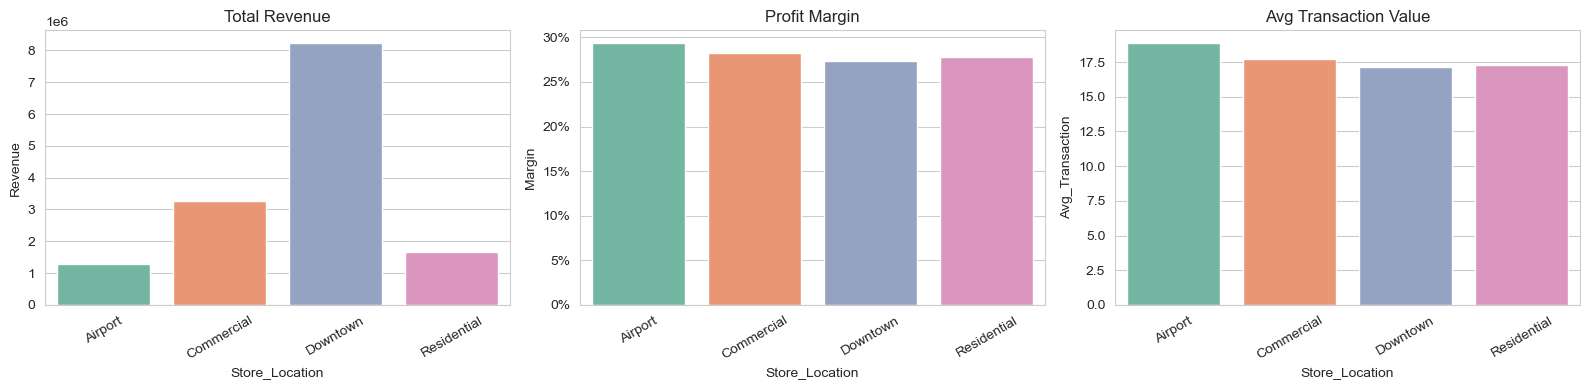

In [8]:
# ---------------------------------------------------------------
# 3.2 By location type
# ---------------------------------------------------------------
location_perf = (
    data.groupby("Store_Location", as_index=False)
        .agg(Revenue=("Revenue", "sum"),
             Profit=("Profit", "sum"),
             Transactions=("Sale_ID", "count"))
)
location_perf["Margin"] = location_perf["Profit"] / location_perf["Revenue"]
location_perf["Avg_Transaction"] = location_perf["Revenue"] / location_perf["Transactions"]

display(location_perf.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes,
                          ["Revenue", "Margin", "Avg_Transaction"],
                          ["Total Revenue", "Profit Margin", "Avg Transaction Value"]):
    sns.barplot(data=location_perf, x="Store_Location", y=col, ax=ax, palette="Set2")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
    if col == "Margin":
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.tight_layout()
plt.show()

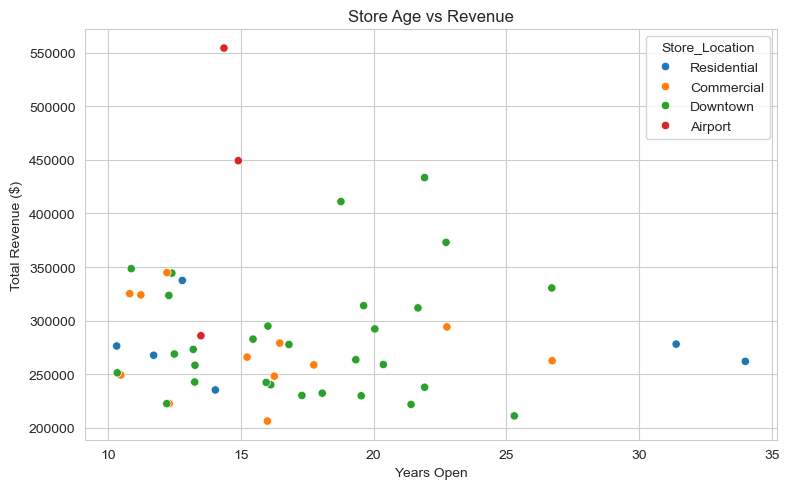

Correlation (Years_Open vs Revenue): -0.054


In [9]:
# ---------------------------------------------------------------
# 3.3 Store age vs performance
# ---------------------------------------------------------------
# Merge open date into store_perf
store_perf = store_perf.merge(
    stores[["Store_ID", "Store_Open_Date"]], on="Store_ID", how="left"
)
store_perf["Years_Open"] = (pd.Timestamp.today() - store_perf["Store_Open_Date"]).dt.days / 365

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=store_perf, x="Years_Open", y="Revenue", hue="Store_Location", ax=ax)
ax.set_title("Store Age vs Revenue")
ax.set_xlabel("Years Open")
ax.set_ylabel("Total Revenue ($)")
plt.tight_layout()
plt.show()

print("Correlation (Years_Open vs Revenue):",
      store_perf["Years_Open"].corr(store_perf["Revenue"]).round(3))

### Findings

- **Top store:** ___ ($X revenue)
- **Bottom store:** ___ ($X revenue)
- **Best location type:** ___ (highest revenue + margin)
- **Store age:** correlation with revenue is ___ → older stores ___ perform better

**Action:** If a small number of stores drive most revenue, consider
whether the bottom performers need local marketing, layout changes,
or (if strategically unimportant) reduced investment.

## 4. Time — How Has Revenue Trended?

Three views:

1. **Monthly revenue** — the headline trend
2. **Seasonality** — which months are strongest across years?
3. **Day-of-week pattern** — do weekends outperform weekdays?

Trend + seasonality together often reveal the biggest operational
opportunities (stocking, staffing, promotions).

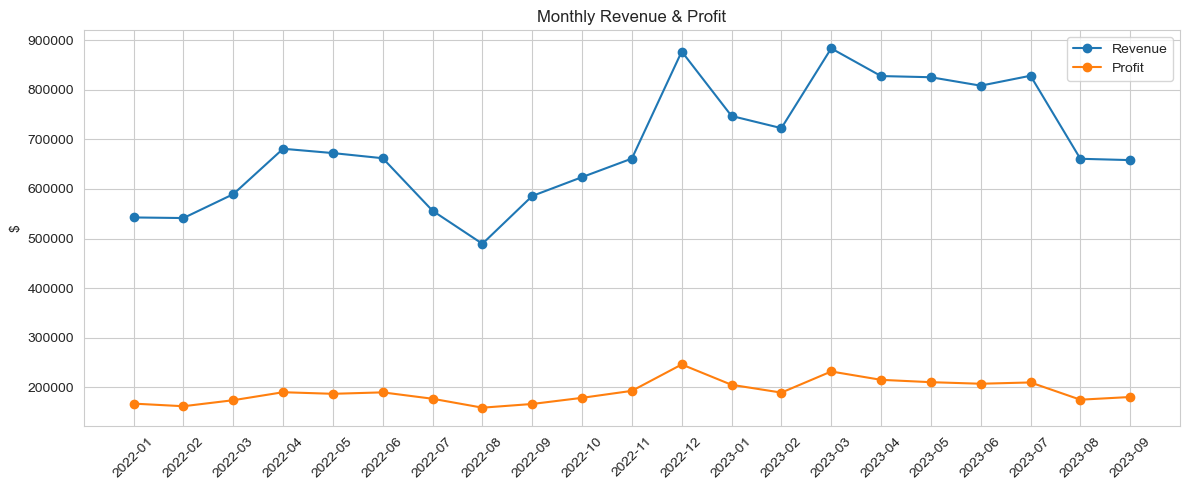

,Month,Revenue,Profit,Units,Margin
0,2022-01,542554.91,167126.0,38009,0.31
1,2022-02,541351.65,161861.0,36935,0.30
2,2022-03,589485.19,173992.0,39981,0.30
3,2022-04,681072.98,190099.0,47102,0.28
4,2022-05,672369.90,186894.0,46910,0.28
5,2022-06,661980.22,189815.0,47178,0.29
6,2022-07,556034.23,176922.0,46177,0.32
7,2022-08,489422.73,158931.0,39927,0.32
8,2022-09,585844.04,166397.0,42196,0.28
9,2022-10,623874.39,178799.0,47861,0.29


In [10]:
# ---------------------------------------------------------------
# 4.1 Monthly revenue
# ---------------------------------------------------------------
monthly = (
    data.groupby("Month", as_index=False)
        .agg(Revenue=("Revenue", "sum"),
             Profit=("Profit", "sum"),
             Units=("Units", "sum"))
)
monthly["Margin"] = monthly["Profit"] / monthly["Revenue"]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["Month"], monthly["Revenue"], marker="o", label="Revenue")
ax.plot(monthly["Month"], monthly["Profit"], marker="o", label="Profit")
ax.set_title("Monthly Revenue & Profit")
ax.set_ylabel("$")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

display(monthly.round(2))

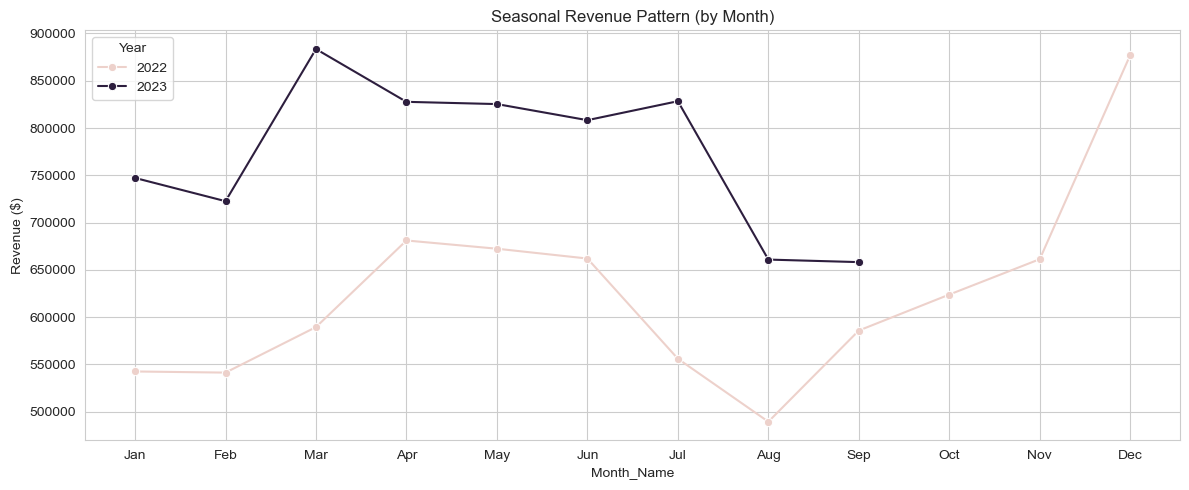

In [11]:
# ---------------------------------------------------------------
# 4.2 Seasonality — month of year across years
# ---------------------------------------------------------------
data["Month_Num"]  = data["Date"].dt.month
data["Month_Name"] = data["Date"].dt.strftime("%b")

seasonal = (
    data.groupby(["Year", "Month_Num", "Month_Name"], as_index=False)
        .agg(Revenue=("Revenue", "sum"))
)
seasonal = seasonal.sort_values(["Year", "Month_Num"])

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=seasonal, x="Month_Name", y="Revenue", hue="Year",
             marker="o", ax=ax)
ax.set_title("Seasonal Revenue Pattern (by Month)")
ax.set_ylabel("Revenue ($)")
plt.tight_layout()
plt.show()

C:\Users\selin\AppData\Local\Temp\ipykernel_14716\1547397902.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dow, x="DayOfWeek", y="Revenue", ax=axes[0], palette="rocket")
C:\Users\selin\AppData\Local\Temp\ipykernel_14716\1547397902.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dow, x="DayOfWeek", y="Transactions", ax=axes[1], palette="mako")


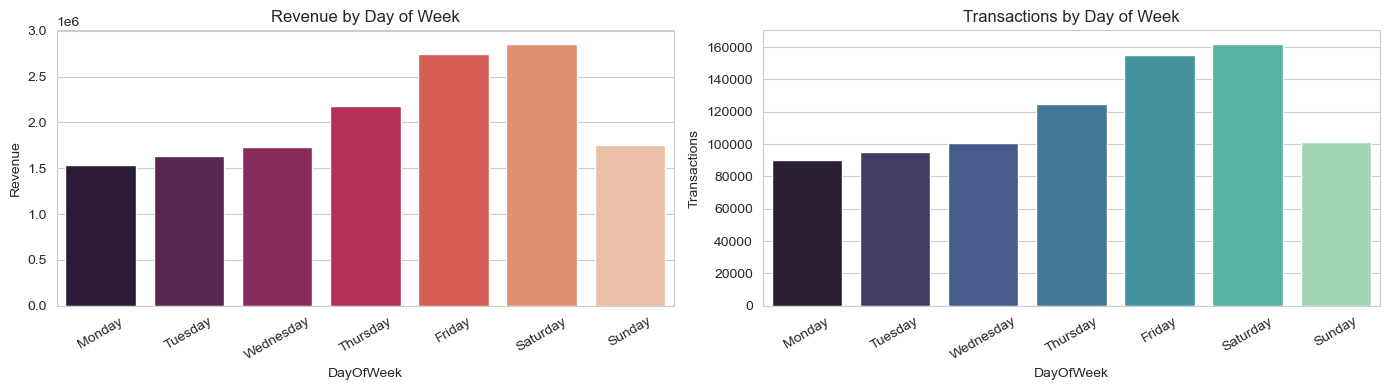

,DayOfWeek,Revenue,Transactions
1,Monday,1531130.01,90332
5,Tuesday,1637492.19,94904
6,Wednesday,1732068.59,100361
4,Thursday,2183641.79,125053
0,Friday,2750302.26,155088
2,Saturday,2860193.51,162164
3,Sunday,1749744.00,101360


In [12]:
# ---------------------------------------------------------------
# 4.3 Day-of-week
# ---------------------------------------------------------------
data["DayOfWeek"] = data["Date"].dt.day_name()

dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = (
    data.groupby("DayOfWeek", as_index=False)
        .agg(Revenue=("Revenue", "sum"),
             Transactions=("Sale_ID", "count"))
)
dow["DayOfWeek"] = pd.Categorical(dow["DayOfWeek"], categories=dow_order, ordered=True)
dow = dow.sort_values("DayOfWeek")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=dow, x="DayOfWeek", y="Revenue", ax=axes[0], palette="rocket")
axes[0].set_title("Revenue by Day of Week")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(data=dow, x="DayOfWeek", y="Transactions", ax=axes[1], palette="mako")
axes[1].set_title("Transactions by Day of Week")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

display(dow)

### Findings

- **Trend:** revenue has been ___ (growing / flat / declining) from ___ to ___
- **Peak month(s):** ___
- **Weakest month(s):** ___
- **Best day of week:** ___  |  **Worst:** ___

**Action:** Align promotional calendars and stock replenishment with
peak months. If the weekend drives disproportionate sales, plan
staffing accordingly.

## 5. Inventory — Where Is Capital Tied Up?

Inventory is money sitting on shelves. We look at:

1. **Total inventory value** and its distribution
2. **Value by category** — which categories lock up the most capital?
3. **Stock coverage** — for each product, how many days of sales does
   current stock represent? (A rough proxy for over/under-stocking)
4. **Out-of-stock risk** — products with zero stock but recent sales

C:\Users\selin\AppData\Local\Temp\ipykernel_14716\1301235548.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=inv_by_cat, x="Product_Category", y="Total_Value",


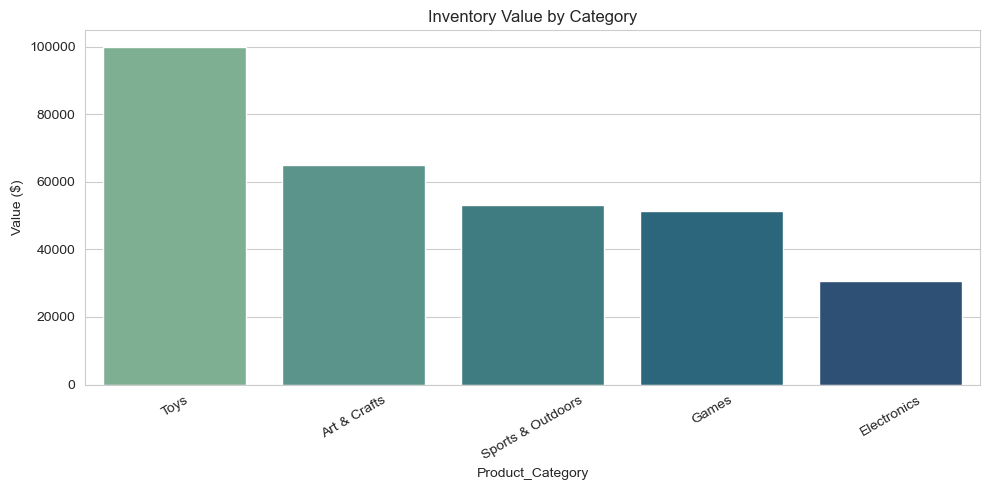

,Product_Category,Total_Value,Total_Stock,SKUs
4,Toys,99861.47,7553,9
0,Art & Crafts,65075.65,8635,8
3,Sports & Outdoors,53077.19,4981,7
2,Games,51489.45,6155,8
1,Electronics,30705.82,2418,3


In [13]:
# ---------------------------------------------------------------
# 5.1 Inventory value by category
# ---------------------------------------------------------------
inv = inventory.merge(products, on="Product_ID", how="left")
inv["Value"] = inv["Stock_On_Hand"] * inv["Product_Cost"]

inv_by_cat = (
    inv.groupby("Product_Category", as_index=False)
       .agg(Total_Value=("Value", "sum"),
            Total_Stock=("Stock_On_Hand", "sum"),
            SKUs=("Product_ID", "nunique"))
       .sort_values("Total_Value", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=inv_by_cat, x="Product_Category", y="Total_Value",
            ax=ax, palette="crest")
ax.set_title("Inventory Value by Category")
ax.set_ylabel("Value ($)")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

display(inv_by_cat.round(2))

In [14]:
# ---------------------------------------------------------------
# 5.2 Stock coverage — days of sales currently covered by stock
# ---------------------------------------------------------------
# Average daily units sold per product over the analysis window
days_in_period = (data["Date"].max() - data["Date"].min()).days + 1

daily_sales = (
    data.groupby("Product_ID", as_index=False)
        .agg(Total_Units=("Units", "sum"))
)
daily_sales["Avg_Daily_Units"] = daily_sales["Total_Units"] / days_in_period

# Total stock across stores per product
stock = inv.groupby("Product_ID", as_index=False).agg(Total_Stock=("Stock_On_Hand", "sum"))

coverage = stock.merge(daily_sales, on="Product_ID", how="left")
coverage["Days_Of_Coverage"] = np.where(
    coverage["Avg_Daily_Units"] > 0,
    coverage["Total_Stock"] / coverage["Avg_Daily_Units"],
    np.nan
)
coverage = coverage.merge(
    products[["Product_ID", "Product_Name"]], on="Product_ID", how="left"
)

print("Products with lowest coverage (potential stock-outs):")
display(coverage.sort_values("Days_Of_Coverage").head(10).round(1))

print("\nProducts with highest coverage (potential overstock):")
display(coverage.sort_values("Days_Of_Coverage", ascending=False).head(10).round(1))

Products with lowest coverage (potential stock-outs):


,Product_ID,Total_Stock,Total_Units,Avg_Daily_Units,Days_Of_Coverage,Product_Name
0,1,614,57958,90.8,6.8,Action Figure
5,6,1159,104368,163.6,7.1,Colorbuds
15,16,181,13054,20.5,8.8,Jenga
2,3,1282,91663,143.7,8.9,Barrel O' Slime
30,31,893,60248,94.4,9.5,Splash Balls
14,15,376,22659,35.5,10.6,Hot Wheels 5-Pack
8,9,649,38236,59.9,10.8,Dino Egg
17,18,1118,59737,93.6,11.9,Lego Bricks
24,25,2129,103128,161.6,13.2,PlayDoh Can
13,14,795,37518,58.8,13.5,Glass Marbles



Products with highest coverage (potential overstock):


,Product_ID,Total_Stock,Total_Units,Avg_Daily_Units,Days_Of_Coverage,Product_Name
28,29,497,5488,8.6,57.8,Plush Pony
34,35,241,2710,4.2,56.7,Uno Card Game
19,20,234,2647,4.1,56.4,Mini Basketball Hoop
25,26,550,6298,9.9,55.7,PlayDoh Playset
27,28,357,4158,6.5,54.8,Playfoam
22,23,709,8605,13.5,52.6,Mr. Potatohead
9,10,2272,29012,45.5,50.0,Dinosaur Figures
31,32,513,6793,10.6,48.2,Supersoaker Water Gun
32,33,483,6416,10.1,48.0,Teddy Bear
3,4,255,3829,6.0,42.5,Chutes & Ladders


In [15]:
# ---------------------------------------------------------------
# 5.3 Out-of-stock risk: zero stock but active sales
# ---------------------------------------------------------------
zero_stock = inv[inv["Stock_On_Hand"] == 0]

# Did these products sell recently?
last_90_days = data["Date"].max() - pd.Timedelta(days=90)
recent_sales = (
    data[data["Date"] >= last_90_days]
    .groupby("Product_ID", as_index=False)
    .agg(Recent_Units=("Units", "sum"))
)

risk = zero_stock.merge(recent_sales, on="Product_ID", how="left")
risk = risk.merge(products[["Product_ID", "Product_Name"]], on="Product_ID", how="left")

n_risk = risk["Recent_Units"].notna().sum()
print(f"Store/product combos with zero stock but recent sales: {n_risk}")
display(risk[risk["Recent_Units"].notna()].head(20))

Store/product combos with zero stock but recent sales: 77


,Store_ID,Product_ID,Stock_On_Hand,Product_Name_x,Product_Category,Product_Cost,Product_Price,Value,Recent_Units,Product_Name_y
0,1,2,0,Animal Figures,Toys,9.99,12.99,0.0,6115,Animal Figures
1,1,5,0,Classic Dominoes,Games,7.99,9.99,0.0,626,Classic Dominoes
2,1,34,0,Toy Robot,Electronics,20.99,25.99,0.0,1552,Toy Robot
3,2,1,0,Action Figure,Toys,9.99,15.99,0.0,4703,Action Figure
4,2,9,0,Dino Egg,Toys,9.99,10.99,0.0,9413,Dino Egg
5,2,11,0,Etch A Sketch,Art & Crafts,10.99,20.99,0.0,2918,Etch A Sketch
6,3,15,0,Hot Wheels 5-Pack,Toys,3.99,5.99,0.0,4030,Hot Wheels 5-Pack
7,3,29,0,Plush Pony,Toys,8.99,19.99,0.0,950,Plush Pony
8,4,34,0,Toy Robot,Electronics,20.99,25.99,0.0,1552,Toy Robot
9,5,11,0,Etch A Sketch,Art & Crafts,10.99,20.99,0.0,2918,Etch A Sketch


### Findings

- **Total inventory value:** $___
- **Category with most capital tied up:** ___ ($___)
- **Products with the lowest stock coverage:** ___ → potential stock-outs
- **Products with the highest coverage:** ___ → possible overstock
- **Zero-stock products that still sold recently:** ___ combos

**Action:**
- Replenish low-coverage products before they stock out
- Consider promotions or reduced reorders on overstocked items
- Investigate zero-stock + recent-sales combos — they represent
  immediate lost sales

## 6. Executive Summary

### The numbers
- Revenue: $___
- Profit: $___ (margin: ___%)
- Units sold: ___
- Inventory value: $___

### What's working
- ___ category / product / store type

### What's not
- ___ losses / overstock / stock-outs

### Recommended actions
1. ___
2. ___
3. ___

### Next steps
- Build a dashboard or scheduled report
- Add forecasting (demand per product/store)
- Add customer-level view if data becomes available

In [16]:
# Export the analysis-ready dataframe (used in any downstream notebooks)
output_dir = Path("C:/Users/selin/anaconda_projects/data science/Retail-Sales-Inventory-Project/data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

data.to_parquet(output_dir / "retail_analysis.parquet", index=False)
print(f"Saved {len(data):,} rows to {output_dir / 'retail_analysis.parquet'}")

Saved 829,262 rows to C:\Users\selin\anaconda_projects\data science\Retail-Sales-Inventory-Project\data\processed\retail_analysis.parquet
